# Problem
## Stiffness and hidden motion from partial laboratory modes
Four story stiffnesses and two unobserved fourth-floor modal amplitudes are inferred from two real shake-table modes measured at floors1–3. The modes are author-processed observations; the fitted stiffness is **not physical ground truth**. We actively reproduce the complete selected inverse and all three published objective comparisons. Numerical solver failures and finite-iteration limitations remain visible.

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,normalize_modes,MASS
from src.physics_model import residual_jacobian,eigenmodes,stiffness_matrix
from src.solvers import reconstruct,solve
from src.visualization import stiffness_figure,relative_error
sp=importlib.util.spec_from_file_location('modal_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(sp);sp.loader.exec_module(judge)
frequency,measured=load_data(ROOT/'data/raw_data.npz');observed,q=normalize_modes(measured)
original=dict(np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False))
print('Observed frequencies (Hz):',frequency,'floor mass (lbf s²/in):',MASS)
print('Observed normalized shapes:\n',observed)

Observed frequencies (Hz): [0.88289843 2.74773779] floor mass (lbf s²/in): 0.031236402063778205
Observed normalized shapes:
 [[ 0.39237461  1.        ]
 [ 0.74620539  0.7201735 ]
 [ 1.         -0.26340767]]


# Data
The laboratory structure has a fixed base, four equal weighed masses and story springs. Only six measured mode entries and two frequencies are exposed. No fourth-floor measured value or unretained higher mode is supplied as calibration or truth. An author's modal-extraction pipeline produced these observations from accelerometer data; this task does not pretend to have the original acceleration traces.

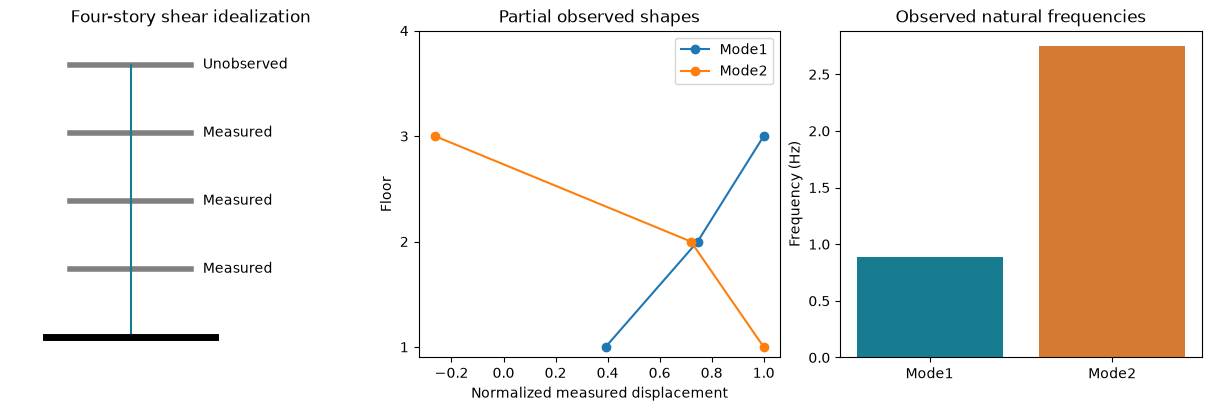

In [2]:
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for floor in range(1,5):
    axes[0].plot([-.5,.5],[floor,floor],lw=4,color='gray');axes[0].plot([0,0],[floor-1,floor],color='#187c91');axes[0].text(.6,floor,'Measured' if floor<4 else 'Unobserved',va='center')
axes[0].plot([-.7,.7],[0,0],'k-',lw=5);axes[0].set(xlim=(-1,2),ylim=(-.3,4.5),title='Four-story shear idealization');axes[0].axis('off')
for i in range(2):axes[1].plot(observed[:,i],np.arange(1,4),'o-',label=f'Mode{i+1}')
axes[1].set(xlabel='Normalized measured displacement',ylabel='Floor',yticks=[1,2,3,4],title='Partial observed shapes');axes[1].legend()
axes[2].bar(['Mode1','Mode2'],frequency,color=['#187c91','#d47a32']);axes[2].set(ylabel='Frequency (Hz)',title='Observed natural frequencies')
plt.show()

# Physics
The free vibration balance is $K u_i=\lambda_i M u_i$, with $\lambda_i=(2\pi f_i)^2$. The drift-vector assembly $K=\sum_j k_jd_jd_j^T$ ensures the energy identity $u^TKu=\sum_j k_j(u_j-u_{j-1})^2$, where the fixed-base displacement is zero. Stiffness is in lbf/in and mass in lbf·s²/in. The latent top-floor amplitude shares the signed normalization of the observed mode. Model mismatch means all equilibrium equations cannot generally be satisfied exactly.

# Method
The main state contains four relative stiffness changes $\alpha_j$ and two latent amplitudes, with $k_j=10(1+\alpha_j)$. We minimize the eight stacked dynamic residuals using bounded nonlinear least squares and twelve starts. The analytic Jacobian contains $K_j u_i$ and the unobserved column of $K-\lambda_iM$. The original verified backend is Octave's supported least-squares implementation; the local backend is SciPy TRF. Both use the same mathematical objective and bounds. Different optimizer paths can enter different basins.

Full primary reconstruction seconds: 0.02145240001846105
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "parameter_relative_error": 8.853362487570848e-12,
    "modal_residual_rms": 0.14665653653024485
  },
  "thresholds": {
    "parameter_relative_error": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "modal_residual_rms": {
      "comparison": "<=",
      "boundary": 0.1613221901832689
    }
  },
  "errors": []
}
Fresh stiffness lbf/in: [[ 7.28144993  7.48956958  8.83616571 15.32971275]]
Fresh latent amplitudes: [[[ 1.07578154 -0.67043433]]]


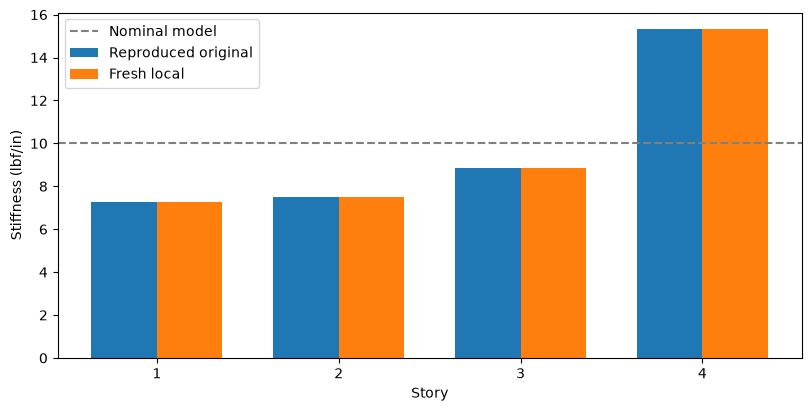

Form 3 original/fresh best objectives 0.17206511765637536 0.17206511765637467 fresh gradient max 2.157439116245996e-09
Form 1 original/fresh best objectives 1.6045850998600367e-07 1.6044187837741494e-07 fresh gradient max 1.5291010577417156e-12
Form 2 original/fresh best objectives 0.0020562316209899265 0.0020562316209900653 fresh gradient max 3.394510304788323e-09


In [3]:
start=time.perf_counter();fresh,runs=reconstruct(frequency,measured);runtime=time.perf_counter()-start
np.savez_compressed(ROOT/'output/reconstruction.npz',**fresh);report=judge.evaluate(ROOT/'output/reconstruction.npz');assert report['passed']
print('Full primary reconstruction seconds:',runtime);print(json.dumps(report,indent=2))
print('Fresh stiffness lbf/in:',fresh['reconstruction']);print('Fresh latent amplitudes:',fresh['unmeasured_modes'])
stiffness_figure(fresh['reconstruction'],original['reconstruction']);plt.show()
comparisons={3:(np.r_[fresh['reconstruction'][0]/10-1,fresh['unmeasured_modes'].ravel()],runs)}
for form in [1,2]:comparisons[form]=solve(frequency,measured,form)
for form,(x,rr) in comparisons.items():
    i=np.argmin(original[f'output_objective_{form}']);best=min(rr,key=lambda d:d['objective'])
    print('Form',form,'original/fresh best objectives',original[f'output_objective_{form}'][i],best['objective'],'fresh gradient max',max(abs(best['gradient'])))

# Results
The method references below are **this task's original runs**, not copied paper metrics. Every fresh comparator was computed above. Form1 uses frequency and MAC discrepancy, form2 frequency and individual shape differences, form3 dynamic equilibrium. Their objective scales differ, so compare original/fresh within each panel rather than ranking objective numbers across panels. Original MAC iteration caps and bad boundary basins are shown explicitly.

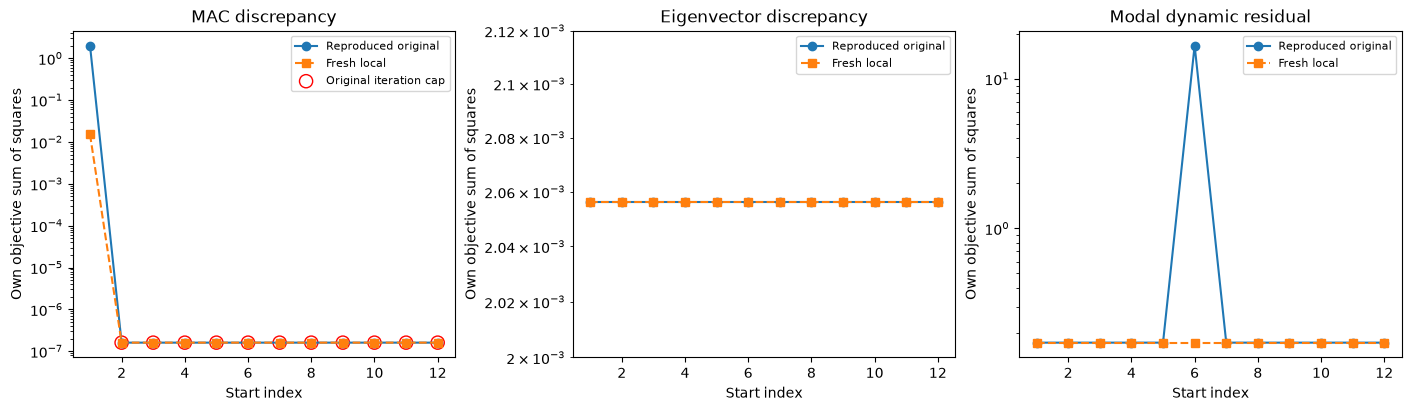

In [4]:
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,form in zip(axes,[1,2,3]):
    oo=original[f'output_objective_{form}'];ee=original[f'output_exit_{form}'];ff=np.array([r['objective'] for r in comparisons[form][1]])
    ax.semilogy(np.arange(1,13),oo,'o-',label='Reproduced original');ax.semilogy(np.arange(1,13),ff,'s--',label='Fresh local')
    failed=ee<=0
    if failed.any():ax.scatter(np.arange(1,13)[failed],oo[failed],s=90,facecolors='none',edgecolors='red',label='Original iteration cap')
    ax.set(xlabel='Start index',ylabel='Own objective sum of squares',title=['MAC discrepancy','Eigenvector discrepancy','Modal dynamic residual'][form-1]);ax.legend(fontsize=8)
    if form==2:ax.set_ylim(.002,.00212)
plt.show()

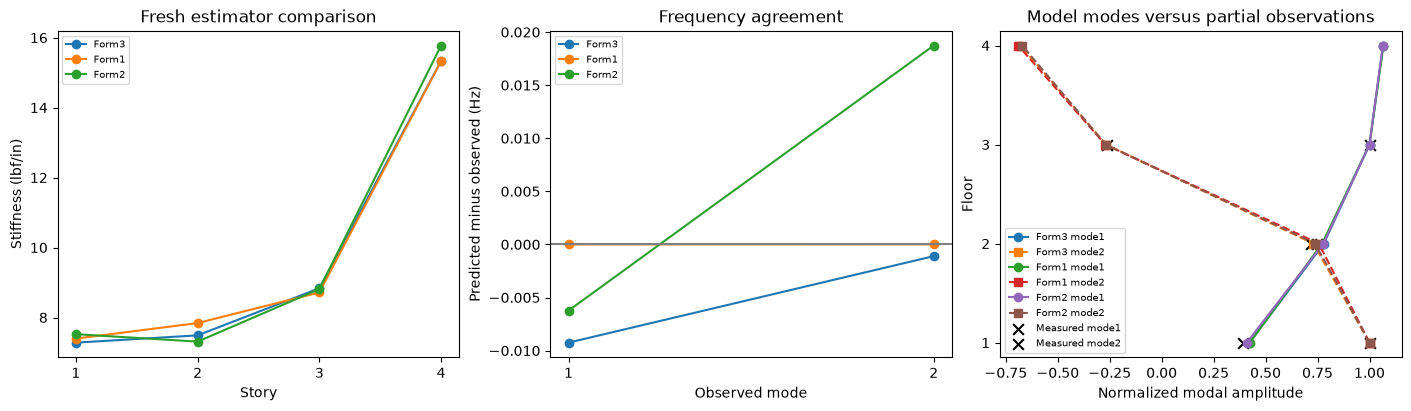

In [5]:
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained');floor=np.arange(1,5)
for form,(x,rr) in comparisons.items():
    lam,v=eigenmodes(x[:4],q);axes[0].plot(np.arange(1,5),10*(1+x[:4]),'o-',label=f'Form{form}')
    axes[1].plot(np.arange(1,3),np.sqrt(lam)/(2*np.pi)-frequency,'o-',label=f'Form{form}')
    axes[2].plot(v[:,0],floor,'o-',label=f'Form{form} mode1');axes[2].plot(v[:,1],floor,'s--',label=f'Form{form} mode2')
axes[0].set(xlabel='Story',ylabel='Stiffness (lbf/in)',title='Fresh estimator comparison',xticks=floor)
axes[1].axhline(0,color='gray');axes[1].set(xlabel='Observed mode',ylabel='Predicted minus observed (Hz)',xticks=[1,2],title='Frequency agreement')
for i in range(2):axes[2].scatter(observed[:,i],floor[:3],color='black',s=60,marker='x',label='Measured mode'+str(i+1))
axes[2].set(xlabel='Normalized modal amplitude',ylabel='Floor',yticks=floor,title='Model modes versus partial observations')
for ax in axes:ax.legend(fontsize=7)
plt.show()

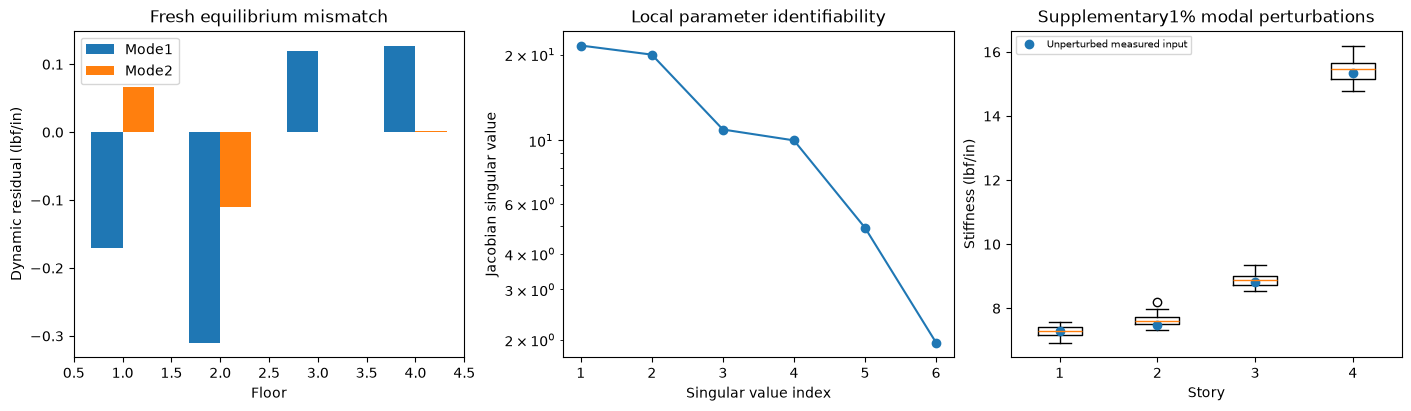

Jacobian singular values: [21.50966053 19.98441503 10.91770229  9.99998813  4.93731803  1.95332825] condition: 11.011800280324518


In [6]:
best=min(runs,key=lambda d:d['objective']);r,J=residual_jacobian(best['x'],frequency,measured)
singular=np.linalg.svd(J,compute_uv=False)
rng=np.random.default_rng(19);perturbed=[]
for trial in range(20):
    fp=frequency*(1+.01*rng.normal(size=2));vp=measured*(1+.01*rng.normal(size=measured.shape))
    xp,_=solve(fp,vp,3,starts=np.array([best['x'][:4]]));perturbed.append(10*(1+xp[:4]))
perturbed=np.array(perturbed)
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for i in range(2):axes[0].bar(np.arange(1,5)+(i-.5)*.32,r.reshape(2,4)[i],.32,label=f'Mode{i+1}')
axes[0].set(xlabel='Floor',ylabel='Dynamic residual (lbf/in)',title='Fresh equilibrium mismatch');axes[0].legend()
axes[1].semilogy(np.arange(1,7),singular,'o-');axes[1].set(xlabel='Singular value index',ylabel='Jacobian singular value',title='Local parameter identifiability')
axes[2].boxplot(perturbed,tick_labels=['1','2','3','4']);axes[2].plot(np.arange(1,5),fresh['reconstruction'][0],'o',label='Unperturbed measured input');axes[2].set(xlabel='Story',ylabel='Stiffness (lbf/in)',title='Supplementary1% modal perturbations');axes[2].legend(fontsize=7)
plt.show();print('Jacobian singular values:',singular,'condition:',singular[0]/singular[-1])
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_measurements.npz',**fresh,runtime_seconds=np.array([runtime]),mdr_residual=r[None],jacobian_singular_values=singular[None],perturbation_stiffness=perturbed[None],**{f'objective_form{form}':np.array([x['objective'] for x in comparisons[form][1]])[None] for form in [1,2,3]})

# Conclusion
The selected dynamic-residual solution reproduces the original best method result and passes fixed physical residual checks, while the alternative objectives give different stiffness interpretations. Original optimizer failures are retained; improved fresh convergence is not mislabeled as identical per-start behavior. The nonzero residual and supplementary perturbation spread show why numerical parity is not proof of physical truth. The two low modes constrain this idealized model only under known mass, boundary and normalization assumptions.